# Lesson 12: Kinetics II: Exchange Current, Overpotential and Tafel Analysis
We now have the Butler-Volmer equation. This lesson puts it to work: we will find the one number that captures how fast a reaction is at equilibrium, and then find the plot that lets you measure it.

Today's topics:
- Exchange current and its relationship to the Nernst equation
- The current-overpotential equation and overpotential
- Tafel analysis, and measuring the transfer coefficient

**Reference:**
- Sections 3.3 and 3.4 in *Electrochemical Methods: Fundamentals and Applications*, Allen J. Bard & Larry R. Faulkner.
---

## Configure Environment

In [7]:
import sys
if '../Resources' not in sys.path:
    sys.path.append('../Resources')     # so that echem.py can be found

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, widgets

import echem                            # the shared toolkit for this course
from echem import R, T, F, f, WIDE      # constants and the two-panel figure size
echem.use_style()                       # course-wide graph formatting

# Reaction coordinates used by the potential energy surface figures below
x_oxidized = np.linspace(0, 2, 50)
x_reduced = np.linspace(1, 3, 50)

# 1. Exploration of the Butler-Volmer Equation

The equation describes the relationship between voltage and current in an electrochemical measurement, which we can see will be exponential in nature.

We can use the equation as a theoretical tool to explore predicted behavior. For example, the measurement of zero current flow does not mean that no chemistry is happening - it means that the anodic and cathodic half reactions are proceeding at exactly the same rate. This is easily visualized using the Butler-Volmer equation, particularly if one assumes that the system is under **kinetic control**. This means that mass transfer does not become limiting during the measurement:

$\large C_O(0,t) = C_O^*$

$\large C_R(0,t) = C_R^*$

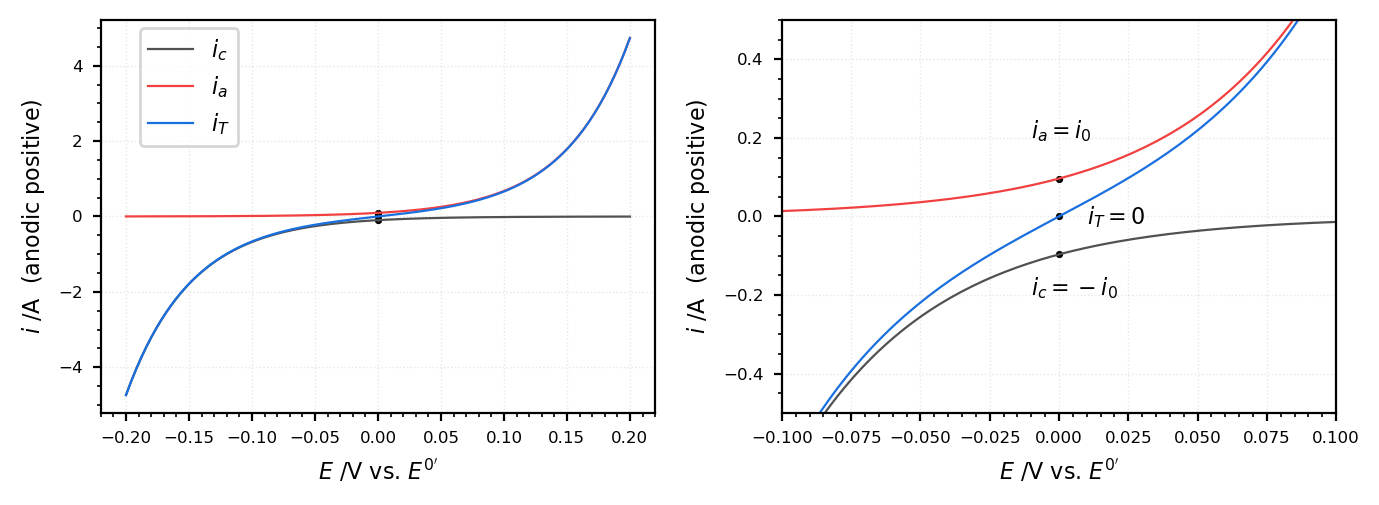

In [8]:
# The two branches of the Butler-Volmer equation, and the exchange current where
# they cross.  Sign convention: ANODIC POSITIVE (see echem.py).
conc_o = 0.001                  # mol/cm3
conc_r = 0.001                  # mol/cm3
area = 1.0                      # cm2
k_0 = 0.001                     # cm/s
alpha = 0.5
potential = np.linspace(-0.2, 0.2, 200)     # V vs E0'

i_a, i_c = echem.butler_volmer_branches(potential, k_0, conc_o, conc_r,
                                        alpha=alpha, area=area)
i_total = i_a + i_c
i_0 = echem.exchange_current(k_0, conc_o, conc_r, alpha=alpha, area=area)

fig = plt.figure(figsize=WIDE)
ax1 = plt.subplot(121)
ax2 = plt.subplot(122)
for ax in [ax1, ax2]:
    ax.set_xlabel(r"$E$ /V vs. $E^{0'}$")
    ax.set_ylabel(r'$i$ /A  (anodic positive)')
    ax.plot(potential, i_c, label=r'$i_c$')
    ax.plot(potential, i_a, label=r'$i_a$')
    ax.plot(potential, i_total, label=r'$i_T$')
    ax.scatter([0]*3, [0, i_0, -i_0], color='black')
ax2.set_xlim(-0.1, 0.1)
ax2.set_ylim(-0.5, 0.5)

ax2.annotate(r'$i_c=-i_0$', (-0.01, -0.2), fontsize=8)
ax2.annotate(r'$i_a=i_0$', (-0.01, 0.2), fontsize=8)
ax2.annotate(r'$i_T=0$', (0.01, -0.02), fontsize=8)
ax1.legend(loc=(0.07, 0.68), fontsize=8)
fig.savefig('../Workspace/component-currents.png')

Notice the points marked on the figure above. At equilibrium the total current is zero, but the components are non-zero. This non-zero value is an important measure of the inherent kinetics of the reaction.

<div class="alert alert-block alert-success">
    <b>Exchange current ($i_0$):</b> the magnitude of anodic and cathodic current flow at equilibrium. This cannot be directly measured because $i_T = 0$.
</div>

Mathematically, the magnitude of the anodic and cathodic branches must be equal:

$
\large i_0 = FAk^0 C_O^*e^{-\alpha F (E_{eq}-E^{0'})/RT} = FAk^0 C_R^*e^{(1-\alpha) F (E_{eq}-E^{0'})/RT}
$

The Nernst equation, which we have seen before, can be written in an exponential form:

$
\large \frac{C_O^*}{C_R^*} = e^{F(E_{eq}-E^{0'})/RT}
$

If we raise the Nernst equation to the power of $\alpha$:

$
\large \left[ \frac{C_O^*}{C_R^*} \right]^\alpha = e^{\alpha F(E_{eq}-E^{0'})/RT}
$

It can be substituted into the exchange current equation above:

$
\large i_0 = FAk^0 C_O^{1-\alpha} C_R^\alpha
$

This is simplified in the situation where $C_O^* = C_R^*$: 

$
\large i_0 = FAk^0C^*
$

# 2. Current-Overpotential Equation

Remember that $k^0$ is a parameter that was defined for a special situation: the bulk concentration of both redox active species must be equal and we must be measuring at $E^{0'}$. It may not always be possible to operate under such conditions. Definition of the exchange current provides us with a far more direct means to study electron transfer kinetics. Division of the **Butler-Volmer equation**:

$
\large i = F A k^0 \left[ C_R(0,t)e^{(1-\alpha) F (E-E^{0'}) / R T} -  C_O(0,t)e^{-\alpha F (E-E^{0'}) / R T} \right]
$

By the **exchange current equation** yields the **current-overpotential equation**.

$
\large i = i_0 \left[ \frac{C_R(0,t)}{C_R^*} e^{(1-\alpha) F \eta / R T} -  \frac{C_O(0,t)}{C_O^*} e^{-\alpha F \eta / R T} \right]
$



This form of the equation has the benefit of working with **overpotential** ($\eta$) rather than ($E - E^{0'}$).  

<div class="alert alert-block alert-success">
    <b>Overpotential ($\eta$):</b> The magnitude of potential applied beyond the equilibrium of the system (where $i$ = 0).
    <br>
    $\large \eta = E - E_{eq}$
</div>

A special case can be defined that greatly facilitates analysis of steady-state kinetics using the current-overpotential equation:

If:

$
\large C_O(0,t) = C_O^*
$

$
\large C_R(0,t) = C_R^*
$

Then:

$
\large i = i_0 \left[ e^{(1-\alpha) F \eta / R T} -  e^{-\alpha F \eta / R T} \right]
$

<div class="alert alert-block alert-info">
<b>Activity:</b> Identify situations where this special case may be realized, write your answers below.
</div>

**Fundamentally, these conditions may occur when:**
- ANSWER
- ANSWER

**Practically, these conditions may occur when:**
- ANSWER
- ANSWER

The two situations worth naming are the ones you will actually meet. **Fundamentally**, the surface concentrations equal the bulk ones whenever the reaction is slow enough that diffusion has no trouble keeping up, which is to say whenever $i \ll i_{lim}$. **Practically**, this is arranged by working at small currents, by stirring, or by making the electrode small, and we will spend [Lesson 14](L14-Mass-Transfer-Limitations.ipynb) onwards learning how to guarantee it.

Note what has been bought here. Once mass transport is out of the way, the entire current-potential relationship depends on a single measurable number.

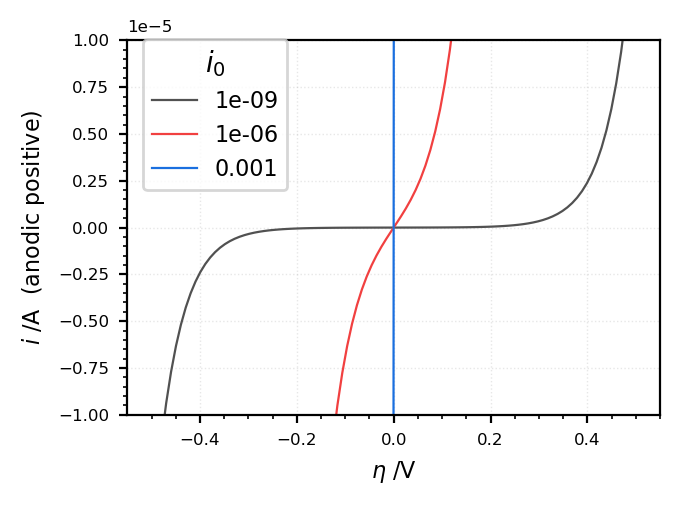

In [9]:
# How the exchange current sets the scale of everything.
exchange_currents = [1e-9, 1e-6, 1e-3]      # A
alpha = 0.5
overpotential = np.linspace(-0.5, 0.5, 100)

fig = plt.figure()
ax1 = plt.subplot(111)
for i_0 in exchange_currents:
    ax1.plot(overpotential, echem.butler_volmer_from_i0(overpotential, i_0, alpha),
             label=i_0)
ax1.set_ylim(-1e-5, 1e-5)
ax1.set_xlabel(r'$\eta$ /V')
ax1.set_ylabel(r'$i$ /A  (anodic positive)')
ax1.legend(loc=(0.03, 0.6), fontsize=8, title=r'$i_0$')
fig.savefig('../Workspace/exchangecurrent.png')

This simplified form of the equation can be applied in two ways:

1. At $\eta$ << 50 mV

$
\large i = i_0 \frac{F}{RT} \eta
$

2.  At $\eta$ >> 50 mV

$
\large ln(i) = ln(i_0) - \frac{\alpha F}{RT}\eta
$

$
\large ln(i) = ln(i_0) + \frac{(1-\alpha) F}{RT}\eta
$

## Micropolarization and Charge Transfer Resistance

The behavior at large overpotentials is the most commonly analyzed, and we will spend the rest of the lesson on it. 

First, a quick detour through the small overpotential regime. The system is very close to equilibrium under these conditions, so both exponentials can be linearised and the current becomes directly proportional to the overpotential. If we group terms that are constants, we can see that this portrays a version of Ohm's law:

$ \large \eta = \left[ \frac{RT}{Fi_0} \right] i = R_{ct}\, i $

<div class="alert alert-block alert-success">
<b>Charge transfer resistance ($R_{ct}$)</b>: the effective resistance of the electron transfer reaction itself, $R_{ct} = RT/nFi_0$. A fast reaction has a large $i_0$ and therefore a <b>small</b> $R_{ct}$.
</div>

This is a genuinely different way to measure $i_0$. A Tafel measurement has to apply significant overpotential and control mass transfer in the system, which risks changing the surface, heating the cell, or violating assumptions underlying the math. A micropolarization measurement stays within a few millivolts of equilibrium and disturbs almost nothing.

In [14]:
# Close to equilibrium the interface is just a resistor.  How close is close?
overpotential = np.linspace(-0.05, 0.05, 300)

@interact(log_i0=widgets.FloatSlider(value=-6.0, min=-9.0, max=-3.0, step=0.5,
                                     description=r'$\log(i_0/A)$'))
def plot_micropolarization(log_i0):
    '''Left: the true curve against its linear approximation.  Right: the error.

    The dashed line is eta/R_ct.  Where it lies on top of the solid line you may
    treat the interface as a resistor; where it does not, you may not.
    '''
    i_0 = 10.0**log_i0
    r_ct = echem.charge_transfer_resistance(i_0)
    true = echem.butler_volmer_from_i0(overpotential, i_0, alpha=0.5)
    linear = overpotential/r_ct

    fig = plt.figure(figsize=WIDE)
    ax1 = plt.subplot(121)
    ax2 = plt.subplot(122)

    ax1.plot(overpotential, true, color='darkred', label='Butler-Volmer')
    ax1.plot(overpotential, linear, linestyle='--', color='gray', label=r'$\eta / R_{ct}$')
    ax1.set_xlabel(r'$\eta$ /V')
    ax1.set_ylabel(r'$i$ /A  (anodic positive)')
    ax1.legend(fontsize=6, loc=2)

    ax2.plot(overpotential, 100*(linear - true)/np.where(true == 0, np.nan, true),
             color='darkred')
    ax2.axhline(5, linestyle=':', color='gray')
    ax2.axhline(-5, linestyle=':', color='gray')
    ax2.set_xlabel(r'$\eta$ /V')
    ax2.set_ylabel('error in linear approx. /%')
    ax2.set_ylim(-20, 20)

    print(f'i_0 = {i_0:.2e} A     R_ct = {r_ct:.3e} ohm')

interactive(children=(FloatSlider(value=-6.0, description='$\\log(i_0/A)$', max=-3.0, min=-9.0, step=0.5), Out…

The linear approximation is better than 1% out to about $\pm 13$ mV and better than 5% out to nearly $\pm 30$ mV, which is where the rough 50 mV boundary in the equations above comes from. And **that window does not move when you change $i_0$**: it is set by $RT/F$, not by the kinetics. Only the slope of the line changes.

<div class="alert alert-block alert-danger">
<b>Check your units, and your resistances!</b>
<br>
For $i_0 = 10^{-3}$ A the cell above reports $R_{ct} \approx 26\ \Omega$. In Lesson 7 we estimated an uncompensated solution resistance $R_u$ of a similar size.
<br>
Your potentiostat measures the sum. Which resistance were you trying to measure, and what would you have to do to separate them?
</div>

We will put $R_{ct}$ aside until [Lesson 31](L31-Electrochemical-Impedance-Spectroscopy.ipynb), where we will learn another way to measure it.

# 3. Tafel Analysis

Based on these equations, semilogarithmic plots (log(i) vs $\eta$) are commonly employed. These are referred to as **Tafel plots**.

In [11]:
exchange_currents = [1e-9, 1e-6, 1e-3]      # A
overpotential = np.linspace(-0.3, 0.3, 100)

@interact(alpha=widgets.FloatSlider(value=0.5, min=0.05, max=0.95, step=0.01,
                                    description=r'$\alpha$'),
          mass_transport=widgets.Checkbox(value=False, description='mass transport'))
def plot_tafel(alpha, mass_transport):
    '''Left: the semilogarithmic (Tafel) view.  Right: the same data, linear axes.

    Tick the box to let the surface concentrations deplete.  The Tafel line then
    rolls over onto the limiting current plateau, and any fit that strays into
    that region reports a slope belonging to diffusion rather than to kinetics.
    '''
    fig = plt.figure(figsize=WIDE)
    ax1 = plt.subplot(121)
    ax2 = plt.subplot(122)
    for i_0 in exchange_currents:
        if mass_transport:
            i_lim = 1e-5                    # A, an arbitrary transport ceiling
            current = i_lim*echem.current_overpotential(overpotential, i_lim/i_0, alpha)
        else:
            current = echem.butler_volmer_from_i0(overpotential, i_0, alpha)
        ax1.plot(overpotential, np.abs(current), label=i_0)
        ax2.plot(overpotential, current, label=i_0)
    ax1.set_yscale('log')

    ax1.set_xlabel(r'$\eta$ /V')
    ax1.set_ylabel(r'$|i|$ /A')
    ax2.set_xlabel(r'$\eta$ /V')
    ax2.set_ylabel(r'$i$ /A  (anodic positive)')
    ax2.set_xlim(-0.1, 0.1)
    ax2.set_ylim(-5e-6, 5e-6)
    ax1.legend(fontsize=6, title=r'$i_0$', loc=4)

interactive(children=(FloatSlider(value=0.5, description='$\\alpha$', max=0.95, min=0.05, step=0.01), Checkbox…

<div class="alert alert-block alert-info">
<b>Activity:</b> Explain why the semilogarithmic plot shows curvature in the ~50 mV region.
</div>

The answer is that a Tafel plot is a plot of one exponential, and near $\eta = 0$ there are two. The cathodic term does not politely vanish the moment the anodic term appears; both contribute, and their difference is not a straight line on logarithmic axes. Only once one branch is perhaps a hundred times the other does the sum collapse to a single exponential and the plot straighten out.

<div class="alert alert-block alert-success">
- A Tafel extrapolation is only valid <b>far</b> from equilibrium, yet the quantity it extrapolates to, $i_0$, is defined <b>at</b> equilibrium. Every Tafel measurement is an extrapolation into a region where the equation used to fit it does not hold.
</div>

That tension is worth sitting with, and it is the reason the micropolarization method above is a genuine alternative rather than a curiosity.

# 4. Measuring the Transfer Coefficient

This parameter is perhaps the most frustrating aspect of electron transfer kinetics. It is important to understand that it is an empirical parameter that attempts to capture the relative symmetry of the two PES. There are flaws in it, but it has proven to be remarkably useful in describing mechanistic behavior.

The value of $\alpha$ is often assumed to be 0.5, but this is not guaranteed. Any substantial change in structure between the reactant and product is almost guaranteed to yield a deviation. These values can be "measured" using the Tafel slopes above. Alternatively, one can design experiments explicitly targeted at measuring $\alpha$ with confidence. Let us consider the exchange current equation once more:

$
\large i_0 = FAk^0 C_O^*e^{-\alpha F (E_{eq}-E^{0'})/RT} = FAk^0 C_R^*e^{(1-\alpha) F (E_{eq}-E^{0'})/RT}
$

If we take the logarithm of one component:

$
\large ln(i_0) = ln(FAk^0) +ln(C_O^*) -\alpha F (E_{eq}-E^{0'})/RT
$

Expanding the equation:

$
\large ln(i_0) = ln(FAk^0) +ln(C_O^*) + \frac{\alpha F E^{0'}}{RT} - \frac{\alpha FE_{eq}}{RT} 
$

Be careful here: $C_O^*$ is **not** independent of $E_{eq}$. Changing $C_O^*$ changes the equilibrium potential too, so the measured slope is the *total* derivative:

$
\large \frac{d\,ln(i_0)}{dE_{eq}} = \frac{d\,ln(C_O^*)}{dE_{eq}} - \frac{\alpha F}{RT}
$

Nernst links the two ($ln(C_O^*) = ln(C_R^*) + F(E_{eq}-E^{0'})/RT$), so at fixed $C_R^*$ the first term is $F/RT$:

$
\large \frac{d\,ln(i_0)}{dE_{eq}} = \frac{F}{RT} - \frac{\alpha F}{RT}
$

$
\large \frac{d\,ln(i_0)}{dE_{eq}} = \frac{(1-\alpha)F}{RT}
$

If the species being measure is a solvated molecule, one can therefore measure $\alpha$ with confidence by:
1. creating a series of solutions with varied $C_O^*$
2. measuring $i_0$ for the system
3. determining the slope from a plot of ln($i_0$) vs. $E_{eq}$

This handling highlights soemthing important: 
- **$i_0$ is not a property of the electrode material alone**. It changges with concentration. **A reported $i_0$ is meaningless without the concentrations it was measured at**.

The example above that demonstrated the individual $i_c$ and $i_a$ components to highlight $i_0$ was created using $C_O^*$ = $C_R^*$. We now see that this behavior needs to be generalized:

In [12]:
area = 1.0      # cm2
k_0 = 0.001     # cm/s
potential = np.linspace(-0.2, 0.2, 200)     # V vs E0'

@interact(conc_o=widgets.FloatText(value=0.001, step=0.0001, description=r'$C_O^*$'),
          conc_r=widgets.FloatText(value=0.001, step=0.0001, description=r'$C_R^*$'),
          alpha=widgets.FloatSlider(value=0.5, min=0.05, max=0.95, step=0.05,
                                    description=r'$\alpha$'))
def plot_varied_concentration(conc_o, conc_r, alpha):
    '''Vary the bulk concentrations and watch both i_0 and E_eq move.'''
    if conc_o <= 0 or conc_r <= 0:
        print('Both concentrations must be greater than zero.')
        return

    i_a, i_c = echem.butler_volmer_branches(potential, k_0, conc_o, conc_r,
                                            alpha=alpha, area=area)
    i_total = i_a + i_c
    i_0 = echem.exchange_current(k_0, conc_o, conc_r, alpha=alpha, area=area)
    idx_eq = echem.nearest_index(i_total, 0.0)      # where the total current crosses zero

    fig = plt.figure(figsize=WIDE)
    ax1 = plt.subplot(121)
    ax2 = plt.subplot(122)
    for ax in [ax1, ax2]:
        ax.set_xlabel(r"$E$ /V vs. $E^{0'}$")
        ax.set_ylabel(r'$i$ /A  (anodic positive)')
        ax.plot(potential, i_c, label=r'$i_c$')
        ax.plot(potential, i_a, label=r'$i_a$')
        ax.plot(potential, i_total, label=r'$i_T$')
        ax.scatter([potential[idx_eq]]*3, [0, i_0, -i_0], color='black')
    ax2.set_xlim(-0.15, 0.15)
    ax2.set_ylim(-0.5, 0.5)
    ax1.legend(loc=(0.07, 0.68), fontsize=8)

    print(f'i_0 = {i_0:.3e} A     E_eq = {potential[idx_eq]:+.3f} V vs E0\'')

interactive(children=(FloatText(value=0.001, description='$C_O^*$', step=0.0001), FloatText(value=0.001, descr…